# Практическая работа №1 — FiresRu.csv

Окружение — отдельный venv (Python, pandas/numpy/matplotlib/pyarrow), запускается
через Jupyter. Ниже — блоки в том же порядке, что и в методичке курса (нумерация
разделов сохранена, чтобы легко сверяться).

### 2.1 Проверка окружения

In [1]:
import sys
import platform
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib
import pyarrow
import matplotlib.pyplot as plt

versions = {
    "Python": sys.version.split()[0],
    "OS": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "pyarrow": pyarrow.__version__,
}
for name, value in versions.items():
    print(f"{name:12s} {value}")

Python       3.12.10
OS           Windows-11-10.0.26200-SP0
pandas       3.0.5
numpy        2.5.3
matplotlib   3.11.2
pyarrow      25.0.1


Все нужные для работы библиотеки (`pandas`, `numpy`, `matplotlib`, `pyarrow`)
импортировались без `ImportError` — значит окружение настроено верно, дальше можно
работать с реальными данными.

### 3.1 Векторизация вместо цикла

Небольшая демонстрация: перевод скорости ветра из м/с в км/ч (`v_kmh = 3.6 * v_ms`)
одной операцией над массивом, без `for`.

In [2]:
speed_ms_demo = np.array([2.05, 0.63, 1.42])
speed_kmh_demo = speed_ms_demo * 3.6
print("м/с:", speed_ms_demo)
print("км/ч:", np.round(speed_kmh_demo, 2))

м/с: [2.05 0.63 1.42]
км/ч: [7.38 2.27 5.11]


Умножение применяется сразу ко всему массиву — этот же приём дальше используется
для целого столбца `wind_speed_ms` в реальной таблице (раздел 6.2).

### 3.2 Series, DataFrame, groupby на игрушечном примере

Прежде чем работать с 26 тысячами строк, полезно увидеть эти операции на трёх
строках, где результат считается в уме.

In [3]:
demo_series = pd.Series([15, 25, 35], name="amount")
demo_frame = pd.DataFrame({"category": ["X", "Y", "X"], "amount": [15, 25, 35]})

print(type(demo_series).__name__)
print(type(demo_frame).__name__)
print(demo_frame.groupby("category")["amount"].sum())

Series
DataFrame
category
X    50
Y    25
Name: amount, dtype: int64


`Series` — один именованный столбец с индексом, `DataFrame` — таблица из
согласованных `Series`. `groupby(...).sum()` разбивает строки по ключу
(`category`) и суммирует `amount` внутри каждой группы — та же логика ниже
применяется к `type_name` в реальных данных.

### 4.1 Загрузка FiresRu.csv

Файл использует запятую как разделитель и кодировку UTF-8, поэтому
`read_csv` отрабатывает без дополнительных параметров.

In [4]:
DATA_PATH = Path("FiresRu.csv")
df = pd.read_csv(DATA_PATH)

print(df.shape)
print(df.columns.tolist())
display(df.head())

(26681, 9)
['type_name', 'type_id', 'lon', 'lat', 'temperature_c', 'precipitation_mm', 'relative_humidity', 'wind_speed_ms', 'solar_radiation']


,type_name,type_id,lon,lat,temperature_c,precipitation_mm,relative_humidity,wind_speed_ms,solar_radiation
0,Natural fire,4,131.5866,47.8662,-9.44,0.01,72.98,1.14,4.59
1,Natural fire,4,131.5885,47.8809,-9.44,0.01,72.98,1.14,4.59
2,Forest fire,3,131.9871,48.4973,-10.71,0.05,81.31,0.80,4.24
3,Natural fire,4,131.9031,43.6277,-7.77,0.00,68.41,0.97,4.66
4,Natural fire,4,131.5706,47.8581,-9.44,0.01,72.98,1.14,4.59


Таблица прочиталась как 26681 строк и 9 столбцов,
что совпадает с описанием набора. Столбца с датой/временем нет, значит построить
временной ряд (сезонность, динамика по месяцам) по этому файлу нельзя.

### 5.1 Структура и память

`info()` печатается через промежуточный буфер `io.StringIO`, чтобы результат
попал в обычный `print` и одновременно был виден расход памяти
(`memory_usage="deep"` учитывает и содержимое текстовых столбцов).

In [5]:
import io

info_stream = io.StringIO()
df.info(buf=info_stream, memory_usage="deep")
print(info_stream.getvalue())

<class 'pandas.DataFrame'>
RangeIndex: 26681 entries, 0 to 26680
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   type_name          26681 non-null  str    
 1   type_id            26681 non-null  int64  
 2   lon                26681 non-null  float64
 3   lat                26681 non-null  float64
 4   temperature_c      26681 non-null  float64
 5   precipitation_mm   26681 non-null  float64
 6   relative_humidity  26681 non-null  float64
 7   wind_speed_ms      26681 non-null  float64
 8   solar_radiation    26681 non-null  float64
dtypes: float64(7), int64(1), str(1)
memory usage: 2.1 MB



Пропусков нет, все 9 столбцов заполнены полностью. `type_name` хранится как
текстовый тип — с пятью повторяющимися значениями на 26 681 строку это явный
кандидат на `category` (см. раздел 6.1).

### 5.2 Пропуски, дубликаты, уникальные значения

In [6]:
print("Пропуски по столбцам:")
print(df.isna().sum())

print("\nПолных дубликатов:", df.duplicated().sum())

print("\nЧисло уникальных значений:")
print(df.nunique())

Пропуски по столбцам:
type_name            0
type_id              0
lon                  0
lat                  0
temperature_c        0
precipitation_mm     0
relative_humidity    0
wind_speed_ms        0
solar_radiation      0
dtype: int64

Полных дубликатов: 0

Число уникальных значений:
type_name                5
type_id                  5
lon                  25708
lat                  23547
temperature_c         2581
precipitation_mm       571
relative_humidity     4028
wind_speed_ms          532
solar_radiation        731
dtype: int64


Пропущенных значений и полных дубликатов нет — удалять строки не за что.
Малая кардинальность `type_name`/`type_id` (по 5 значений) — признак того, что
это категориальные поля, а не непрерывные величины.

### 5.3 Проверка соответствия type_id и type_name

Если бы одному коду соответствовало несколько названий (или наоборот) — это была
бы ошибка данных. Проверяю явно.

In [7]:
type_map = (
    df[["type_id", "type_name"]]
    .drop_duplicates()
    .sort_values("type_id")
)
print(type_map.to_string(index=False))

 type_id         type_name
       1 Uncontrolled burn
       2         Peat fire
       3       Forest fire
       4      Natural fire
       5   Controlled burn


Соответствие взаимно однозначное: 5 кодов на 5 названий. Значит `type_id` можно
безопасно хранить компактным целым типом, но использовать его как число в
статистике (например считать среднее) некорректно — это код категории.

### 5.4 Описательная статистика

`type_id` в статистику не включаю намеренно — это категориальный код, а не
измеряемая величина.

In [8]:
numeric_cols = [
    "lon", "lat", "temperature_c", "precipitation_mm",
    "relative_humidity", "wind_speed_ms", "solar_radiation",
]
display(df[numeric_cols].describe().round(2).T)

,count,mean,std,min,25%,50%,75%,max
lon,26681.0,106.35,27.31,20.37,82.41,96.56,133.90,175.87
lat,26681.0,57.53,4.30,41.71,53.95,58.97,60.64,70.33
temperature_c,26681.0,17.89,5.68,-34.88,15.70,19.08,21.39,31.94
precipitation_mm,26681.0,0.46,1.46,0.00,0.00,0.04,0.30,25.85
relative_humidity,26681.0,69.44,11.43,24.70,62.93,71.35,77.91,99.83
wind_speed_ms,26681.0,0.63,0.93,0.00,0.11,0.25,0.66,7.42
solar_radiation,26681.0,5.57,1.50,0.42,4.55,5.68,6.71,8.97


Температура лежит в диапазоне от −34,88 до 31,94 °C при медиане 19,08 °C.
У осадков и скорости ветра медиана намного ближе к нулю, чем максимум
(0,04 против 25,85 мм; 0,25 против 7,42 м/с) — оба распределения явно
асимметричны, это стоит проверить на гистограмме.

### 6.1 Оптимизация dtype

Работаю с копией `prepared_df`, чтобы не терять исходный `df`. `type_name`
перевожу в `category` (пять повторяющихся строк), `type_id` — в `int8`
(диапазон значений 1–5 подтверждён в разделе 5.3).

In [9]:
prepared_df = df.copy()

mem_before = prepared_df.memory_usage(deep=True).sum()

prepared_df["type_name"] = prepared_df["type_name"].astype("category")
prepared_df["type_id"] = prepared_df["type_id"].astype("int8")

mem_after = prepared_df.memory_usage(deep=True).sum()

print(f"До:      {mem_before / 1024**2:.2f} MiB")
print(f"После:   {mem_after / 1024**2:.2f} MiB")
print(f"Экономия: {(1 - mem_after / mem_before) * 100:.1f}%")

До:      2.13 MiB
После:   1.48 MiB
Экономия: 30.8%


Информация не теряется — исходные значения восстанавливаются из кодов category
и int8 без изменений, но память сокращается на
31%. В версии методички
экономия выше (~53%), но там таблица считалась для старого текстового `object`
dtype pandas 2.x — в pandas 3.0.5, установленной здесь, текст по умолчанию уже
хранится в более компактном `str` dtype, поэтому выигрыш от `category` меньше,
хоть и всё равно заметный.

### 6.2 Вычисляемые признаки

`wind_speed_kmh` — то же измерение в другой единице (не добавляет новой
информации, но удобнее для отчёта). `is_forest_fire` — бинарный индикатор
принадлежности к самому частому классу, пригодится для фильтрации.

In [10]:
prepared_df["wind_speed_kmh"] = (prepared_df["wind_speed_ms"] * 3.6).round(2)
prepared_df["is_forest_fire"] = prepared_df["type_name"] == "Forest fire"

display(prepared_df[[
    "type_name", "wind_speed_ms", "wind_speed_kmh", "is_forest_fire"
]].head())

,type_name,wind_speed_ms,wind_speed_kmh,is_forest_fire
0,Natural fire,1.14,4.10,False
1,Natural fire,1.14,4.10,False
2,Forest fire,0.80,2.88,True
3,Natural fire,0.97,3.49,False
4,Natural fire,1.14,4.10,False


`wind_speed_kmh` — линейное преобразование единиц измерения, `is_forest_fire` —
логический признак категории. Оба вычислены векторно, без циклов по строкам.

### 7.1 Распределение наблюдений по типам события

In [11]:
type_counts = (
    df["type_name"]
    .value_counts()
    .to_frame("n")
    .assign(share_pct=lambda x: (x["n"] / len(df) * 100).round(2))
)
display(type_counts)

,n,share_pct
type_name,,
Forest fire,18415,69.02
Natural fire,5195,19.47
Uncontrolled burn,2711,10.16
Controlled burn,333,1.25
Peat fire,27,0.10


Forest fire — 69.02%
всех строк (18415 наблюдений), а
Peat fire — только
0.10%
(27 наблюдений). Классы сильно
несбалансированы — это важно при сравнении групп и при возможной классификации
(accuracy доминирующего класса будет высокой даже у бесполезной модели).

### 7.2 Групповые средние (несколько агрегатов за один проход)

In [12]:
group_stats = (
    df.groupby("type_name", observed=True)
      .agg(
          n=("type_name", "size"),
          temp_mean=("temperature_c", "mean"),
          precip_mean=("precipitation_mm", "mean"),
          humidity_mean=("relative_humidity", "mean"),
          wind_mean=("wind_speed_ms", "mean"),
          solar_mean=("solar_radiation", "mean"),
      )
      .sort_values("n", ascending=False)
      .round(2)
)
display(group_stats)

,n,temp_mean,precip_mean,humidity_mean,wind_mean,solar_mean
type_name,,,,,,
Forest fire,18415,18.69,0.50,70.30,0.42,5.87
Natural fire,5195,17.42,0.40,69.07,0.80,5.14
Uncontrolled burn,2711,14.21,0.29,64.35,1.64,4.57
Controlled burn,333,10.78,0.25,69.46,1.46,4.27
Peat fire,27,18.17,0.55,65.47,1.19,5.26


Смотрю сначала на `n`, а потом на средние: у Peat fire всего 27 наблюдений, и
сравнивать его статистику напрямую с Forest fire (18 415 строк) на равных
нельзя — оценка по маленькой группе гораздо менее устойчива. Средние описывают
конкретную выборку, а не доказывают, что погода определяет тип события.

### 7.3 Условная фильтрация

Отбираю наблюдения с влажностью ниже 40% и ветром сильнее 2 м/с — учебный
составной фильтр, а не норматив пожарной опасности. Для разнообразия использую
`query()` вместо `loc[]` — тоже входит в список методов, которые нужно уметь
применять.

In [13]:
subset = df.query("relative_humidity < 40 and wind_speed_ms > 2")[
    ["type_name", "lon", "lat", "temperature_c", "relative_humidity", "wind_speed_ms"]
]

print("Строк в срезе:", len(subset), f"({len(subset) / len(df) * 100:.2f}% набора)")
display(subset.head())

Строк в срезе: 337 (1.26% набора)


,type_name,lon,lat,temperature_c,relative_humidity,wind_speed_ms
295,Forest fire,91.3929,51.0574,15.15,27.97,2.55
478,Forest fire,104.5843,50.3723,14.67,37.89,2.64
479,Forest fire,104.4937,50.3592,14.67,37.89,2.64
480,Forest fire,104.4187,50.3302,14.67,37.89,2.64
481,Forest fire,104.3001,50.3377,14.67,37.89,2.64


Условию соответствуют 337 строк
(1.26% набора) — редкая, но не
единичная подвыборка одновременно сухих и ветреных наблюдений.

### 8.1 Корреляционная матрица

Только погодные признаки — координаты и `type_id` сюда не годятся, это не
величины, между которыми осмысленно искать линейную связь.

In [14]:
weather_cols = [
    "temperature_c", "precipitation_mm", "relative_humidity",
    "wind_speed_ms", "solar_radiation",
]
corr = df[weather_cols].corr().round(3)
display(corr)

,temperature_c,precipitation_mm,relative_humidity,wind_speed_ms,solar_radiation
temperature_c,1.000,0.003,-0.155,-0.297,0.221
precipitation_mm,0.003,1.000,0.232,-0.047,-0.192
relative_humidity,-0.155,0.232,1.000,-0.280,-0.234
wind_speed_ms,-0.297,-0.047,-0.280,1.000,-0.189
solar_radiation,0.221,-0.192,-0.234,-0.189,1.000


Сильных линейных связей нет: по модулю максимум около 0,3
(temperature_c и wind_speed_ms: r ≈ -0.297;
relative_humidity и wind_speed_ms: r ≈ -0.280).
Это умеренно слабые связи, и они не говорят ничего о причинности.

### 8.2 Правило IQR на примере скорости ветра

In [15]:
q1 = df["wind_speed_ms"].quantile(0.25)
q3 = df["wind_speed_ms"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (df["wind_speed_ms"] < lower_bound) | (df["wind_speed_ms"] > upper_bound)

print(f"Q1={q1:.3f}; Q3={q3:.3f}; IQR={iqr:.3f}")
print(f"Границы: [{lower_bound:.3f}; {upper_bound:.3f}]")
print(f"Кандидатов: {outlier_mask.sum()} ({outlier_mask.mean() * 100:.2f}% строк)")

Q1=0.110; Q3=0.660; IQR=0.550
Границы: [-0.715; 1.485]
Кандидатов: 3652 (13.69% строк)


Правило 1,5·IQR помечает 3652 наблюдений
(13.69% строк) — доля слишком большая, чтобы
списывать это на ошибки измерения. Скорее у скорости ветра тяжёлый правый
хвост распределения. Это список "на проверку", решение об удалении без
проверки источника принимать нельзя.

### 9.1 Bar chart — сравнение категорий

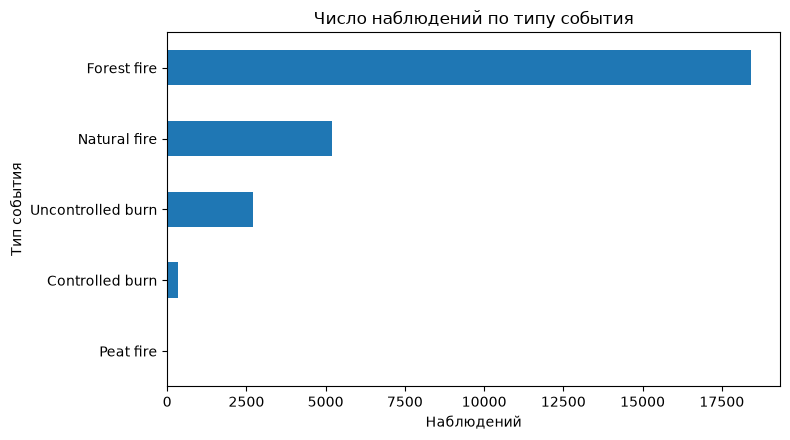

In [16]:
counts_sorted = df["type_name"].value_counts().sort_values()

ax = counts_sorted.plot(kind="barh", figsize=(8, 4.5))
ax.set_title("Число наблюдений по типу события")
ax.set_xlabel("Наблюдений")
ax.set_ylabel("Тип события")
plt.tight_layout()
plt.show()

Дисбаланс виден сразу: Forest fire на порядок больше остальных категорий,
Peat fire едва различим на графике.

### 9.2 Histogram — форма распределения температуры

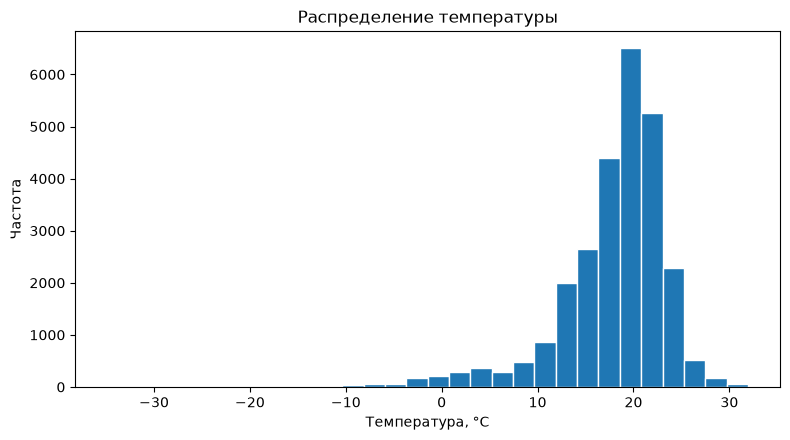

In [17]:
plt.figure(figsize=(8, 4.5))
plt.hist(df["temperature_c"], bins=30, edgecolor="white")
plt.title("Распределение температуры")
plt.xlabel("Температура, °C")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

Основная масса значений — в положительной зоне, но есть заметный левый хвост
с отрицательными температурами. Сам по себе график не доказывает, что это
ошибки — нужна проверка происхождения таких точек.

### 9.3 Scatter plot — температура и влажность

Полные 26 681 точек перегрузили бы график, поэтому беру воспроизводимую
подвыборку.

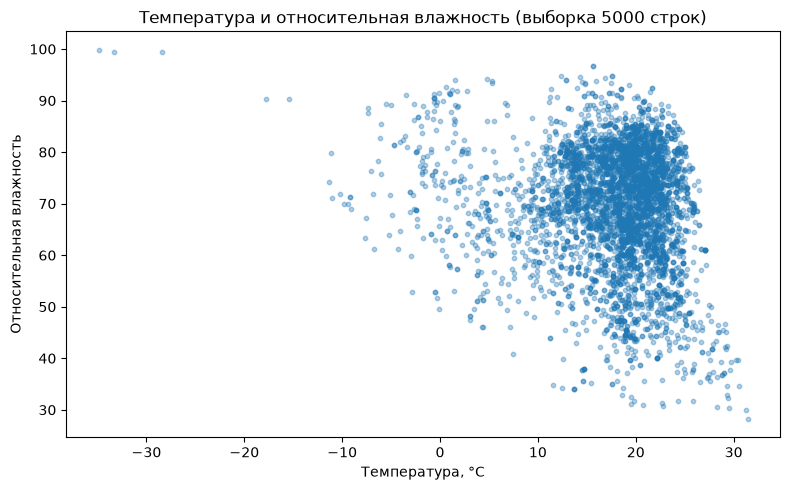

In [18]:
sample = df.sample(n=5000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample["temperature_c"], sample["relative_humidity"], s=10, alpha=0.35)
plt.title("Температура и относительная влажность (выборка 5000 строк)")
plt.xlabel("Температура, °C")
plt.ylabel("Относительная влажность")
plt.tight_layout()
plt.show()

Облако широкое и без чёткой линейной формы — согласуется с невысокой
корреляцией из раздела 8.1. Тенденция к снижению влажности с ростом
температуры есть, но разброс велик.

### 9.4 Пространственный scatter plot по категориям

Координаты рисуются на обычных декартовых осях — это разведочный график
геометрии точек, а не географическая карта.

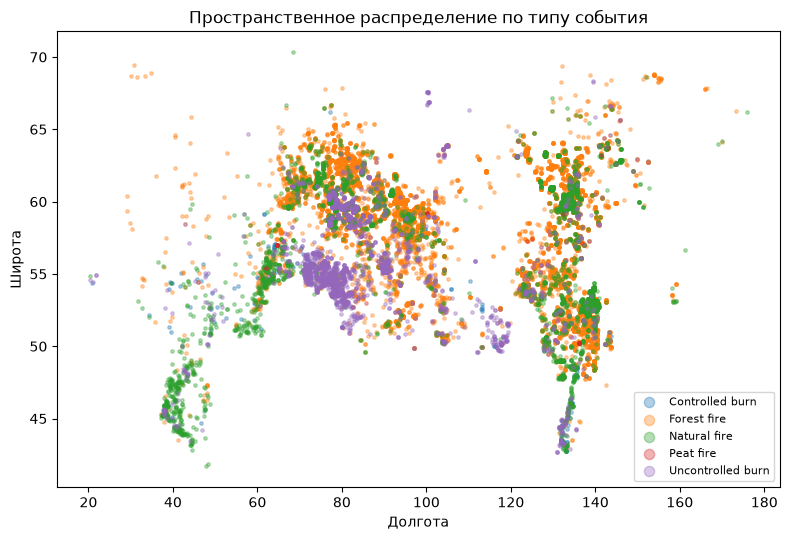

In [19]:
plt.figure(figsize=(8, 5.5))
for name, part in df.groupby("type_name", observed=True):
    plt.scatter(part["lon"], part["lat"], s=6, alpha=0.35, label=name)
plt.title("Пространственное распределение по типу события")
plt.xlabel("Долгота")
plt.ylabel("Широта")
plt.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

Точки растянуты по очень широкому диапазону долгот — набор пространственно
неоднороден, а категории заметно перекрываются в одних и тех же регионах.
Для полноценной географической интерпретации нужны были бы проекция и границы
регионов — здесь это только разведочная геометрия выборки.

### 10.1 Экспорт в CSV, JSON и Parquet

Сохраняю один и тот же `prepared_df` в трёх форматах в отдельную папку
`output`, чтобы сравнение размеров было честным — отличается только формат
хранения, а не содержимое.

In [20]:
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

prepared_df.to_csv(OUT_DIR / "FiresRu_prepared.csv", index=False, encoding="utf-8")
prepared_df.to_json(OUT_DIR / "FiresRu_prepared.json", orient="records", lines=True, force_ascii=False)
prepared_df.to_parquet(OUT_DIR / "FiresRu_prepared.parquet", index=False, engine="pyarrow", compression="snappy")

for path in OUT_DIR.glob("FiresRu_prepared.*"):
    print(f"{path.name:26s} {path.stat().st_size / 1024:8.1f} KB")

FiresRu_prepared.csv         1784.4 KB
FiresRu_prepared.json        5953.2 KB
FiresRu_prepared.parquet      620.8 KB


Parquet заметно компактнее CSV и JSON Lines за счёт колоночного хранения и
сжатия snappy, хотя внутри — ровно та же таблица.

### 10.2 Проверка round-trip

In [21]:
csv_back = pd.read_csv(OUT_DIR / "FiresRu_prepared.csv")
parquet_back = pd.read_parquet(OUT_DIR / "FiresRu_prepared.parquet")

print("CSV:", csv_back.shape)
print("Parquet:", parquet_back.shape)

print("\ntype_name / type_id после CSV:")
print(csv_back[["type_name", "type_id"]].dtypes.to_string())

print("\ntype_name / type_id после Parquet:")
print(parquet_back[["type_name", "type_id"]].dtypes.to_string())

CSV: (26681, 11)
Parquet: (26681, 11)

type_name / type_id после CSV:
type_name      str
type_id      int64

type_name / type_id после Parquet:
type_name    category
type_id          int8


После CSV `type_name`/`type_id` снова стали обычными текстом/int64 — текстовый
формат не хранит схему, типы распознаются заново при каждом чтении. Parquet
восстановил `category` и `int8` без дополнительного кода — схема хранится
вместе с данными, поэтому дальше в курсе (Spark) будет использоваться именно
этот формат.

## 11. Итоговые выводы по FiresRu.csv

1. Таблица содержит 26 681 строку и 9 исходных признаков; пропусков и полных
   дубликатов не обнаружено.
2. Представлено 5 типов событий, Forest fire занимает 69,02% строк, Peat fire —
   только 0,10% (27 наблюдений); классы сильно несбалансированы.
3. `type_id` — категориальный код (проверено взаимно однозначным соответствием
   с `type_name`), использовать его как число в статистике некорректно.
4. Приведение `type_name` к `category` и `type_id` к `int8` уменьшает память
   таблицы без потери информации.
5. Температура лежит в диапазоне от −34,88 до 31,94 °C, медиана 19,08 °C; ряд
   метеопризнаков распределён асимметрично.
6. Линейные корреляции между погодными признаками невысокие — по модулю не
   больше примерно 0,3.
7. Правило 1,5·IQR отмечает значительную долю значений `wind_speed_ms` как
   потенциальные выбросы — это сигнал для проверки, а не основание удалять
   строки автоматически.
8. В файле нет даты/времени, поэтому анализ сезонности или динамики по годам
   на одном FiresRu.csv невозможен.
9. Координаты позволяют посмотреть пространственное распределение категорий,
   но для полноценной картографии нужны GIS-инструменты и границы регионов.

**Ограничения:** `relative_humidity` и `solar_radiation` не имеют единиц
измерения, явно заданных в метаданных файла, поэтому конкретную физическую
единицу для них нельзя утверждать как факт. Корреляция сама по себе не
доказывает причинно-следственную связь.